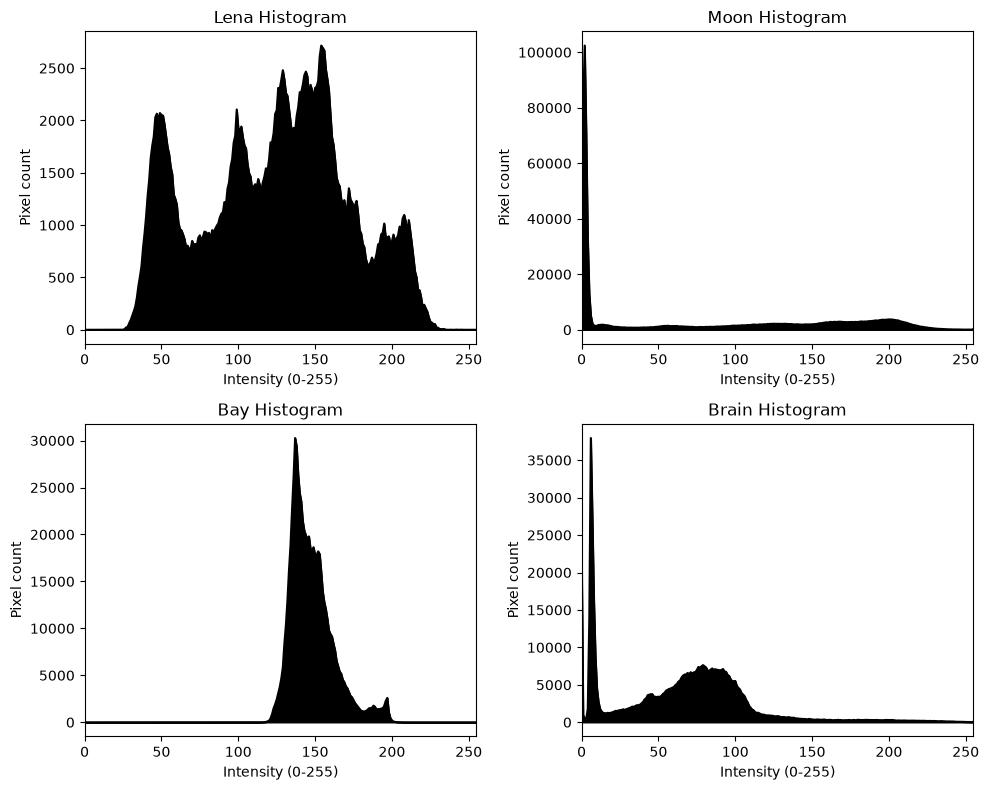

In [36]:
from io import BytesIO
from urllib.request import urlopen
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

Lena = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/lena2.tif")
Moon = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/moon.jpg")
Bay = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/bay.jpg")
Brain = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/brain.jpg")

with urlopen(Lena) as response:
    lena = Image.open(BytesIO(response.read())) 
with urlopen(Moon) as response:
    moon = Image.open(BytesIO(response.read())) 
with urlopen(Bay) as response:
    bay = Image.open(BytesIO(response.read()))  
with urlopen(Brain) as response:
    brain = Image.open(BytesIO(response.read()))

images = {"Lena": lena,"Moon": moon,"Bay": bay,"Brain": brain,}

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

black = "black"

for ax, (name, image) in zip(axes.flat, images.items()):
    pixels = np.asarray(image)
    histogram, _ = np.histogram(pixels.ravel(), bins=256, range=(0, 256))
    intensities = np.arange(256)

    ax.fill_between(intensities, histogram, color=black, alpha=1.0)
    ax.plot(intensities, histogram, color=black)
    ax.set_xlabel("Intensity (0-255)")
    ax.set_ylabel("Pixel count")
    ax.set_title(f"{name} Histogram")
    ax.set_xlim(0, 255)

plt.tight_layout()
plt.show()